<a href="https://colab.research.google.com/github/Makiato1999/2023Web-Bootcamp-Notes/blob/main/anomaly_detection_cnn_autoencoders_cnn_exp.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [71]:
import torch, os, platform, sys
print("PyTorch:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())
!nvidia-smi

PyTorch: 2.9.0+cu126
CUDA available: True
Sat Dec  6 05:09:32 2025       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 550.54.15              Driver Version: 550.54.15      CUDA Version: 12.4     |
|-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  NVIDIA L4                      Off |   00000000:00:03.0 Off |                    0 |
| N/A   58C    P0             29W /   72W |     377MiB /  23034MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----

In [72]:
import numpy as np
np.set_printoptions(suppress=True)
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.io import arff
from sklearn.model_selection import train_test_split
import matplotlib
import os
from types import SimpleNamespace
from sklearn.metrics import f1_score, accuracy_score, recall_score

matplotlib.rcParams["figure.figsize"] = (6, 4)
plt.style.use("ggplot")

import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import TensorDataset, Dataset, DataLoader

# Download dataset

In [73]:
import kagglehub

# Download latest version
path = kagglehub.dataset_download("shayanfazeli/heartbeat")

print("Path to dataset files:", path)

Using Colab cache for faster access to the 'heartbeat' dataset.
Path to dataset files: /kaggle/input/heartbeat


In [74]:
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

/kaggle/input/heartbeat/ptbdb_abnormal.csv
/kaggle/input/heartbeat/ptbdb_normal.csv
/kaggle/input/heartbeat/mitbih_test.csv
/kaggle/input/heartbeat/mitbih_train.csv


# Dataset: Segmented and Preprocessed ECG Signals for Heartbeat

Remark: All the samples are cropped, downsampled and padded with zeroes if necessary to the fixed dimension of 188.

Each of these CSV files contain a matrix, with each row representing an example in that portion of the dataset. The final element of each row denotes the class to which that example belongs.

Source: https://www.kaggle.com/datasets/shayanfazeli/heartbeat/data?select=ptbdb_normal.csv

In [75]:
normal_df = pd.read_csv("/kaggle/input/heartbeat/ptbdb_normal.csv").iloc[:, :-1]
anomaly_df = pd.read_csv("/kaggle/input/heartbeat/ptbdb_abnormal.csv").iloc[:, :-1]
normal_df.head()

,1.000000000000000000e+00,9.003241658210754395e-01,3.585899472236633301e-01,5.145867168903350830e-02,4.659643396735191345e-02,1.268233358860015869e-01,1.333063244819641113e-01,1.191247999668121338e-01,1.106158867478370667e-01,1.130470037460327148e-01,...,0.000000000000000000e+00.55,0.000000000000000000e+00.56,0.000000000000000000e+00.57,0.000000000000000000e+00.58,0.000000000000000000e+00.59,0.000000000000000000e+00.60,0.000000000000000000e+00.61,0.000000000000000000e+00.62,0.000000000000000000e+00.63,0.000000000000000000e+00.64
0,1.000000,0.794681,0.375387,0.116883,0.000000,0.171923,0.283859,0.293754,0.325912,0.345083,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
1,0.909029,0.791482,0.423169,0.186712,0.000000,0.007836,0.063032,0.077002,0.074957,0.077342,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
2,1.000000,0.478893,0.056760,0.064176,0.081289,0.072732,0.055619,0.048774,0.054478,0.041643,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
3,1.000000,0.867238,0.201360,0.099349,0.141336,0.120934,0.108516,0.096393,0.093436,0.100828,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
4,0.948983,0.505265,0.004176,0.022513,0.059550,0.107298,0.110385,0.111293,0.116558,0.118192,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


# Exploratory Data Analysis

In [76]:
print("Shape of Normal data", normal_df.shape)
print("Shape of Abnormal data", anomaly_df.shape)

Shape of Normal data (4045, 187)
Shape of Abnormal data (10505, 187)


# Configuration

In [77]:
from dataclasses import dataclass

@dataclass
class Config:
    epochs: int = 50
    learning_rate: float = 0.001
    batch_size: int = 64
    use_augmentation: bool = False
    input_dim: int = 187
    latent_dim: int = 32
    device: str = 'cuda' if torch.cuda.is_available() else 'cpu'
    save_path: str = './checkpoints'
    model_name: str = 'best_autoencoder.pth'
    channels: int = 128
    kernel_size: int = 3


config = Config(
    epochs=50,
    learning_rate=0.001,
    batch_size=64,
    use_augmentation=True,
    input_dim = 187,
    latent_dim = 8,
    device='cuda' if torch.cuda.is_available() else 'cpu',
    channels = 128,
    kernel_size = 3
)

# Normal-only Scaler

1.对优化更友好

  每一维特征都大致是零均值，梯度传播更稳定；

  不会出现某些 time-step 只在小范围抖动，非常“扁平”。

2.对异常检测更清晰

  normal 的误差分布会更集中在一个统一尺度；

  anomaly 更容易在这个尺度上“冲出去”。

In [78]:
normal = normal_df.to_numpy().astype(np.float64)
# anomaly = anomaly_df.to_numpy().astype(np.float64)
anomaly = anomaly_df.sample(frac=0.10, random_state=42).to_numpy().astype(np.float64)

In [79]:
from types import SimpleNamespace

def split_normal_data(normal, anomaly, seed=45):
    X_train, X_temp = train_test_split(
        normal, test_size=0.30, random_state=seed, shuffle=True
    )

    X_validate, X_test = train_test_split(
        X_temp, test_size=0.50, random_state=seed, shuffle=True
    )

    return SimpleNamespace(
        train=X_train,
        val=X_validate,
        test=X_test,
        anomaly=anomaly
    )

data_split = split_normal_data(normal, anomaly)

X_train = data_split.train
X_validate = data_split.val
X_test = data_split.test
anomaly = data_split.anomaly
print("Train:", X_train.shape)
print("Valid:", X_validate.shape)
print("Test :", X_test.shape)

Train: (2831, 187)
Valid: (607, 187)
Test : (607, 187)


In [80]:
# Normal-only Scaler
from sklearn.preprocessing import StandardScaler
from types import SimpleNamespace

def scaler_data(X_train, X_validate, X_test, anomaly):
  scaler = StandardScaler()
  scaler.fit(X_train)   # 只用 normal 训练集拟合

  X_train_scaled    = scaler.transform(X_train)
  X_validate_scaled = scaler.transform(X_validate)
  X_test_scaled     = scaler.transform(X_test)
  anomaly_scaled    = scaler.transform(anomaly)

  print("Train:", X_train_scaled.shape)
  print("Valid:", X_validate_scaled.shape)
  print("Test :", X_test_scaled.shape)

  return SimpleNamespace(
    X_train_scaled=X_train_scaled,
    X_validate_scaled=X_validate_scaled,
    X_test_scaled=X_test_scaled,
    anomaly_scaled=anomaly_scaled,
    scaler=scaler
  )

In [81]:
class AnomalyDetectionDataset(Dataset):
    """
    PyTorch Dataset for Autoencoder Anomaly Detection.
    X = Y = input itself.
    """
    def __init__(self, np_array):
        self.data = torch.from_numpy(np_array).float()

    def __len__(self):
        return len(self.data)

    def __getitem__(self, idx):
        x = self.data[idx]
        return x, x   # 自编码器需要 X=Y

In [82]:
def get_datasets(data_split, use_scaled = False):
  if use_scaled:
    scaled = scaler_data(
        data_split.train,
        data_split.val,
        data_split.test,
        data_split.anomaly
    )
    X_train = scaled.X_train_scaled
    X_val   = scaled.X_validate_scaled
    X_test  = scaled.X_test_scaled
    anomaly = scaled.anomaly_scaled
  else:
    X_train = data_split.train
    X_val   = data_split.val
    X_test  = data_split.test
    anomaly = data_split.anomaly

  train_ds = AnomalyDetectionDataset(X_train)
  val_ds   = AnomalyDetectionDataset(X_val)
  test_ds  = AnomalyDetectionDataset(X_test)
  anom_ds  = AnomalyDetectionDataset(anomaly)

  return SimpleNamespace(
      train=train_ds,
      val=val_ds,
      test=test_ds,
      anomaly=anom_ds
  )

In [83]:
# 6. DataLoaders
BATCH_SIZE = config.batch_size

# datasets = get_datasets(data_split, use_scaled=False)
datasets = get_datasets(data_split, use_scaled=True)


train_dataset = datasets.train
validate_dataset = datasets.val
test_dataset = datasets.test
anomaly_dataset = datasets.anomaly

train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True, num_workers=4)
validate_loader = DataLoader(validate_dataset, batch_size=BATCH_SIZE, shuffle=False)
test_loader = DataLoader(test_dataset, batch_size=BATCH_SIZE, shuffle=False)
anomaly_loader = DataLoader(anomaly_dataset, batch_size=BATCH_SIZE, shuffle=False)

print("Train batches:", len(train_loader))
print("Valid batches:", len(validate_loader))
print("Test batches :", len(test_loader))
print("Anomaly batches:", len(anomaly_loader))

Train: (2831, 187)
Valid: (607, 187)
Test : (607, 187)
Train batches: 45
Valid batches: 10
Test batches : 10
Anomaly batches: 17


# Normal-only Data Augmentation
好处 1: 减少误报

normal 的误差分布会变得更集中且更低。

好处 2: 真正的 anomaly 会更突出

因为 AE 见过“正常的变化”，它不会被小噪声骗到；
只有 “真正离谱的” 才会变成稳定的大 reconstruction error

In [84]:
import random

def augment_ecg(batch, jitter_std=0.01, scale_std=0.05, max_shift=2):
    """
    batch: (B, 188)
    """
    B, T = batch.shape

    # 1. jitter 小噪声
    jitter = torch.randn_like(batch) * jitter_std
    batch = batch + jitter

    # 2. scaling 幅度缩放
    # scale = 1.0 + torch.randn(B, 1, device=batch.device) * scale_std
    scale = 1.0 + torch.randn_like(batch[:, :1]) * scale_std
    batch = batch * scale

    # 3. small time shift 小平移
    shift = random.randint(-max_shift, max_shift)
    batch = torch.roll(batch, shifts=shift, dims=1)

    return batch


# CNN Autoencoder Model

In [85]:
torch.manual_seed(1024)

class AutoEncoder(nn.Module):
    def __init__(self, input_dim, latent_dim, config: Config):
        super(AutoEncoder, self).__init__()

        # --- 1. Encoder ---
        # Conv1d 输入: (Batch, Channel=1, Length=input_dim)
        self.encoder = nn.Sequential(
            # Layer 1: Conv1D(128, 3) + BN + MaxPool
            nn.Conv1d(in_channels=1, out_channels=config.channels, kernel_size=config.kernel_size, stride=1, padding=1),
            nn.BatchNorm1d(config.channels),
            nn.ReLU(),
            nn.MaxPool1d(kernel_size=2, stride=2, padding=1),

            # Layer 2: Conv1D(128, 3) + BN + MaxPool
            nn.Conv1d(in_channels=config.channels, out_channels=config.channels, kernel_size=config.kernel_size, stride=1, padding=1),
            nn.BatchNorm1d(config.channels),
            nn.ReLU(),
            nn.MaxPool1d(kernel_size=2, stride=2, padding=1),

            # Layer 3: Conv1D(latent_dim, 3) + BN + MaxPool
            nn.Conv1d(in_channels=config.channels, out_channels=latent_dim, kernel_size=config.kernel_size, stride=1, padding=1),
            nn.BatchNorm1d(latent_dim),
            nn.ReLU(),
            nn.MaxPool1d(kernel_size=2, stride=2, padding=1)
        )

        # --- 2. Decoder Conv 部分（不改变长度，只变 channel） ---
        self.decoder_conv = nn.Sequential(
            # Layer 1: Transpose(latent_dim -> latent_dim)
            nn.ConvTranspose1d(in_channels=latent_dim, out_channels=latent_dim, kernel_size=config.kernel_size, stride=1, padding=1),
            nn.BatchNorm1d(latent_dim),
            nn.ReLU(),

            # Layer 2: Transpose(latent_dim -> 128)
            nn.ConvTranspose1d(in_channels=latent_dim, out_channels=config.channels, kernel_size=config.kernel_size, stride=1, padding=1),
            nn.BatchNorm1d(config.channels),
            nn.ReLU(),

            # Layer 3: Transpose(128 -> 128)
            nn.ConvTranspose1d(in_channels=config.channels, out_channels=config.channels, kernel_size=config.kernel_size, stride=1, padding=1),
            nn.BatchNorm1d(config.channels),
            nn.ReLU()
        )

        # --- 3. 自动计算 "encoder + decoder_conv" 之后的 Flatten 大小 ---
        # 关键修复：用整个 encoder→decoder_conv 的输出决定 Linear 的 in_features
        self._flatten_size = self._get_flatten_size(input_dim, latent_dim)

        # --- 4. Dense + Sigmoid 输出到原始维度 ---
        self.decoder_dense = nn.Linear(self._flatten_size, input_dim)

        # 数据是 0-1 归一化，建议用 Sigmoid 把输出压回 [0,1]
        self.final_activation = nn.Identity()

    def _get_flatten_size(self, input_dim, latent_dim):
        """
        用一条假数据跑完整个 encoder + decoder_conv，
        自动推断 Flatten 之后的 feature 维度，保证和 forward 里的 view 一致。
        """
        dummy_input = torch.zeros(1, 1, input_dim)   # shape: [1, 1, 187]
        with torch.no_grad():
            encoded = self.encoder(dummy_input)      # [1, latent_dim, L_enc]
            decoded = self.decoder_conv(encoded)     # [1, 128, L_dec]
        # 展平成 [1, flatten_size]
        return decoded.view(1, -1).size(1)

    def forward(self, x):
        # x shape: [Batch, 187]

        # 1. Reshape for Conv1d: [Batch, 187] -> [Batch, 1, 187]
        x = x.unsqueeze(1)

        # 2. Encoder: [B, 1, 187] -> [B, latent_dim, L_enc]
        encoded = self.encoder(x)

        # 3. Decoder Conv Block: [B, latent_dim, L_enc] -> [B, 128, L_dec]
        decoded = self.decoder_conv(encoded)

        # 4. Flatten: [B, 128, L_dec] -> [B, flatten_size]
        decoded = decoded.view(decoded.size(0), -1)

        # 5. Dense to input_dim
        reconstructed = self.decoder_dense(decoded)

        # 6. Sigmoid 把输出压回 [0,1] 区间
        reconstructed = self.final_activation(reconstructed)

        return reconstructed

In [86]:
def train_model(model, train_loader, val_loader, config: Config):
    device = torch.device(config.device)
    model = model.to(device)

    # 优化器使用 config 中的学习率
    optimizer = optim.Adam(model.parameters(), lr=config.learning_rate)
    criterion = nn.L1Loss()

    # 初始化用于记录 Loss 的字典 (为了最后画图用)
    history = {'train_loss': [], 'val_loss': []}

    best_val_loss = float('inf')

    print(f"Start training on {config.device} for {config.epochs} epochs...")

    for epoch in range(config.epochs):

        # --- Training Phase ---
        model.train()
        train_loss = 0.0

        for batch_idx, (data, _) in enumerate(train_loader):
            # 使用 config.device
            data = data.to(config.device)

            # 使用 config.use_augmentation
            if config.use_augmentation:
                # 假设 augment_ecg 是你定义好的函数
                data_aug = augment_ecg(data).to(config.device)
            else:
                data_aug = data

            optimizer.zero_grad()
            outputs = model(data_aug)
            loss = criterion(outputs, data) # 注意：Target 通常是原始未增强的数据
            loss.backward()
            optimizer.step()

            train_loss += loss.item()

        avg_train_loss = train_loss / len(train_loader)

        # --- Validation Phase ---
        model.eval()
        val_loss = 0.0
        with torch.no_grad():
            for batch, _ in val_loader:
                batch = batch.to(config.device)
                outputs = model(batch)
                loss = criterion(outputs, batch)
                val_loss += loss.item()

        avg_val_loss = val_loss / len(val_loader)

        history['train_loss'].append(avg_train_loss)
        history['val_loss'].append(avg_val_loss)

        print(f"Epoch [{epoch+1}/{config.epochs}] Train Loss: {avg_train_loss:.6f} | Val Loss: {avg_val_loss:.6f}")

        # --- Save Best Model ---
        if avg_val_loss < best_val_loss:
            best_val_loss = avg_val_loss

            # 确保目录存在，不存在则创建
            if not os.path.exists(config.save_path):
                os.makedirs(config.save_path)

            # 拼接完整路径
            save_full_path = os.path.join(config.save_path, config.model_name)

            torch.save(model.state_dict(), save_full_path)
            print(f"  >>> Best model saved to {save_full_path}!")

    print("Training Complete.")
    return history

In [87]:
from copy import deepcopy

config64 = deepcopy(config)
config64.channels = 64

config128 = deepcopy(config)
config128.channels = 128

config256 = deepcopy(config)
config256.channels = 256

config64.model_name = "ae_ch64.pt"
config128.model_name = "ae_ch128.pt"
config256.model_name = "ae_ch256.pt"

🚀 Training Started...
Start training on cuda for 50 epochs...
Epoch [1/50] Train Loss: 0.434691 | Val Loss: 0.390805
  >>> Best model saved to ./checkpoints/best_autoencoder.pth!
Epoch [2/50] Train Loss: 0.290490 | Val Loss: 0.238969
  >>> Best model saved to ./checkpoints/best_autoencoder.pth!
Epoch [3/50] Train Loss: 0.240297 | Val Loss: 0.225310
  >>> Best model saved to ./checkpoints/best_autoencoder.pth!
Epoch [4/50] Train Loss: 0.217304 | Val Loss: 0.220779
  >>> Best model saved to ./checkpoints/best_autoencoder.pth!
Epoch [5/50] Train Loss: 0.226240 | Val Loss: 0.189455
  >>> Best model saved to ./checkpoints/best_autoencoder.pth!
Epoch [6/50] Train Loss: 0.208113 | Val Loss: 0.179771
  >>> Best model saved to ./checkpoints/best_autoencoder.pth!
Epoch [7/50] Train Loss: 0.204589 | Val Loss: 0.179563
  >>> Best model saved to ./checkpoints/best_autoencoder.pth!
Epoch [8/50] Train Loss: 0.191621 | Val Loss: 0.186664
Epoch [9/50] Train Loss: 0.201375 | Val Loss: 0.192837
Epoch [10

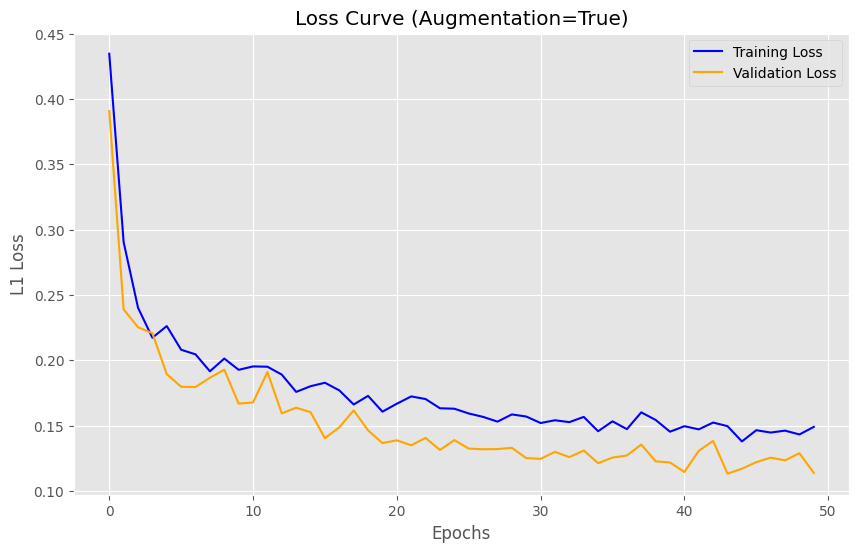

In [88]:
model = AutoEncoder(input_dim=config.input_dim, latent_dim=config.latent_dim, config=config256)
print("🚀 Training Started...")
history = train_model(model, train_loader, validate_loader, config)

plt.figure(figsize=(10, 6))
plt.plot(history['train_loss'], label='Training Loss', color='blue')
plt.plot(history['val_loss'], label='Validation Loss', color='orange')
plt.title(f'Loss Curve (Augmentation={config.use_augmentation})')
plt.xlabel('Epochs')
plt.ylabel('L1 Loss')
plt.legend()
plt.grid(True)
plt.show()

In [89]:
def compute_raw_mae(model, loader, scaler, device="cuda"):
    model.eval()
    mae_list = []

    with torch.no_grad():
        for batch, _ in loader:
            batch = batch.to(device)

            # ---- AE 重建（在 scaled 空间）----
            recon = model(batch)           # (B,187)

            # ---- 转成 numpy ----
            orig = batch.cpu().numpy()     # scaled space
            recon = recon.cpu().numpy()

            # ---- inverse transform 回 raw space ----
            orig_raw = scaler.inverse_transform(orig)
            recon_raw = scaler.inverse_transform(recon)

            # ---- MAE in raw space ----
            mae = np.mean(np.abs(orig_raw - recon_raw), axis=1)  # 每条样本一个 MAE
            mae_list.append(mae)

    mae_list = np.concatenate(mae_list)
    return mae_list

In [90]:
# 计算 Normal / Test / Anomaly 数据集的 Raw-Space MAE
scaler = StandardScaler()
scaler.fit(X_train)

raw_mae_train = compute_raw_mae(model, train_loader, scaler)
raw_mae_validate = compute_raw_mae(model, validate_loader, scaler)
raw_mae_test = compute_raw_mae(model, test_loader, scaler)
raw_mae_anomaly = compute_raw_mae(model, anomaly_loader, scaler)

print("Training raw-space MAE: ", raw_mae_train.mean())
print("Testing raw-space MAE :", raw_mae_test.mean())
print("Anomaly raw-space MAE:", raw_mae_anomaly.mean())

Training raw-space MAE:  0.014981353
Testing raw-space MAE : 0.016013693
Anomaly raw-space MAE: 0.0331835


# Calculate Accuracy / Precision / Recall / F1

In [91]:
def find_threshold_statistical(loss):
    """
    设定阈值为 Mean + 1 * STD。
    (Mean + 2*STD 会更严格，Acc更高但Recall更低；Mean + 1*STD Recall更高)
    """
    mean_loss = loss.mean()
    std_loss = loss.std()

    # 设定阈值: 均值 + 1倍标准差 (为了高 Recall)
    threshold = mean_loss + 1.0 * std_loss

    print(f"统计学阈值 (Mean + 1*STD): {threshold:.5f}")
    return threshold

threshold = find_threshold_statistical(raw_mae_train)

统计学阈值 (Mean + 1*STD): 0.01905


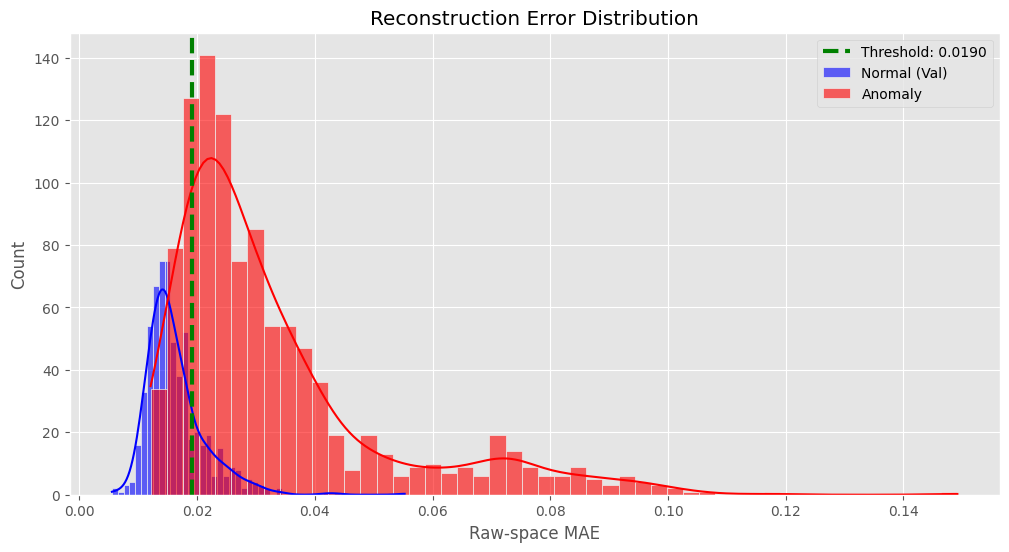

In [92]:
plt.figure(figsize=(12, 6))

# Normal（可以用 val 或 test，看你想展示哪个）
sns.histplot(raw_mae_validate, bins=50, kde=True, color='blue', label='Normal (Val)', alpha=0.6)

# Anomaly
sns.histplot(raw_mae_anomaly, bins=50, kde=True, color='red', label='Anomaly', alpha=0.6)

# 阈值线
plt.axvline(threshold, color='green', linestyle='--', linewidth=3, label=f'Threshold: {threshold:.4f}')

plt.title("Reconstruction Error Distribution")
plt.xlabel("Raw-space MAE")
plt.legend()
plt.show()


In [93]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

print("\n=== 最终测试结果 ===")

# ---- Normal Test 集 (全是正常) ----
# GT: 0 ；预测：MAE > 阈值 → 1（异常）
y_test_true = np.zeros_like(raw_mae_test)  # [0,0,0,...]
y_test_pred = (raw_mae_test > threshold).astype(int)

# ---- Anomaly 集 (全是异常) ----
y_anom_true = np.ones_like(raw_mae_anomaly)  # [1,1,1,...]
y_anom_pred = (raw_mae_anomaly > threshold).astype(int)

# ---- 合并，用做总体评估 ----
y_true = np.concatenate([y_test_true, y_anom_true])
y_pred = np.concatenate([y_test_pred, y_anom_pred])

acc = accuracy_score(y_true, y_pred)
prec = precision_score(y_true, y_pred)
rec = recall_score(y_true, y_pred)
f1 = f1_score(y_true, y_pred)

print(f"Overall Accuracy:  {acc*100:.2f}%")
print(f"Precision (Anom):  {prec*100:.2f}%")
print(f"Recall (Anom):     {rec*100:.2f}%")
print(f"F1 Score:          {f1*100:.2f}%")



=== 最终测试结果 ===
Overall Accuracy:  83.46%
Precision (Anom):  89.27%
Recall (Anom):     84.00%
F1 Score:          86.56%


In [94]:
# Normal Test Accuracy: 在 normal test 集里，有多少被判成 0（正常）
normal_acc = np.mean(y_test_pred == 0)

# Anomaly Recall: 在 anomaly 集里，有多少被判成 1（异常）
anomaly_recall = np.mean(y_anom_pred == 1)

print(f"\n[Summary]")
print(f"Normal Test Accuracy: {normal_acc:.2%}")
print(f"Anomaly Recall:       {anomaly_recall:.2%}")



[Summary]
Normal Test Accuracy: 82.54%
Anomaly Recall:       84.00%


解释一下格子含义（因为你是 anomaly detection，这个很重要）：

cm[0,0] = TN：正常 → 判成 正常

cm[0,1] = FP：正常 → 判成 异常（误报）

cm[1,0] = FN：异常 → 判成 正常（漏报）

cm[1,1] = TP：异常 → 判成 异常（抓对）

Confusion Matrix:
[[501 106]
 [168 882]]


<Figure size 500x500 with 0 Axes>

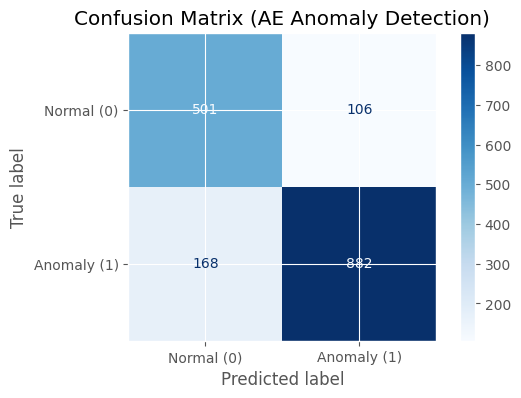

In [95]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

# 计算混淆矩阵
cm = confusion_matrix(y_true, y_pred, labels=[0, 1])

print("Confusion Matrix:")
print(cm)

# 可视化
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=['Normal (0)', 'Anomaly (1)'])
plt.figure(figsize=(5, 5))
disp.plot(cmap='Blues', values_format='d')
plt.title("Confusion Matrix (AE Anomaly Detection)")
plt.show()


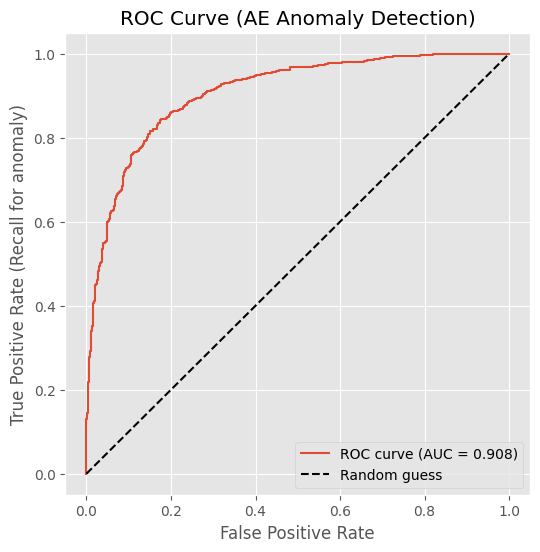

In [96]:
from sklearn.metrics import roc_curve, roc_auc_score

# 拼接 Normal Test 和 Anomaly 的 MAE 作为分数
y_scores = np.concatenate([raw_mae_test, raw_mae_anomaly])  # 连续分数，越大越异常
# y_true 已经在前面拼接过了

fpr, tpr, thresholds = roc_curve(y_true, y_scores)
auc = roc_auc_score(y_true, y_scores)

plt.figure(figsize=(6, 6))
plt.plot(fpr, tpr, label=f"ROC curve (AUC = {auc:.3f})")
plt.plot([0, 1], [0, 1], 'k--', label="Random guess")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate (Recall for anomaly)")
plt.title("ROC Curve (AE Anomaly Detection)")
plt.legend(loc="lower right")
plt.grid(True)
plt.show()


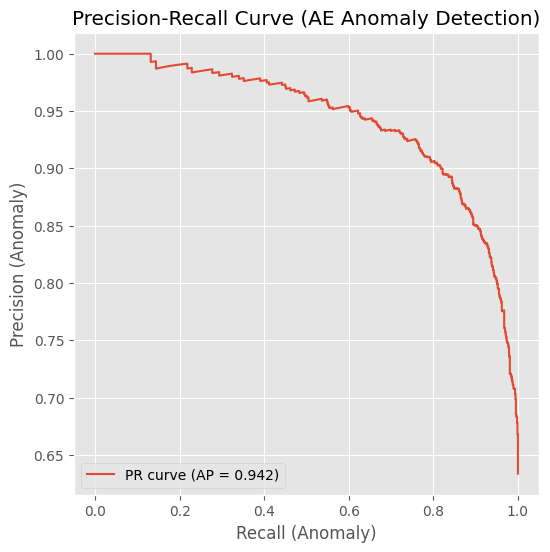

In [97]:
from sklearn.metrics import precision_recall_curve, average_precision_score

precision, recall, thresholds_pr = precision_recall_curve(y_true, y_scores)
ap = average_precision_score(y_true, y_scores)

plt.figure(figsize=(6, 6))
plt.plot(recall, precision, label=f"PR curve (AP = {ap:.3f})")
plt.xlabel("Recall (Anomaly)")
plt.ylabel("Precision (Anomaly)")
plt.title("Precision-Recall Curve (AE Anomaly Detection)")
plt.legend(loc="lower left")
plt.grid(True)
plt.show()


宽度实验：通道数（channels）对建模能力的影响